# Importancia das variaveis nos cinco modelos de predicao de obito por chikungunya

Este notebook calcula a importancia nativa de cada uma das 28 variaveis preditoras para os cinco algoritmos ja treinados na fase de modelagem: Regressao Logistica, Arvore de Decisao (CART), Random Forest, XGBoost e LightGBM.
Os cinco modelos usados aqui foram retreinados depois que uma etapa anterior do pipeline de dados identificou e removeu do conjunto de preditores uma variavel derivada com vazamento temporal, reduzindo o numero de variaveis originais de 29 para 28.
Este notebook recalcula do zero toda a importancia de variaveis com os cinco modelos retreinados nessa nova versao do conjunto de preditores, substituindo integralmente os resultados anteriores, que ainda incluiam a variavel removida.
Para os quatro modelos baseados em arvore, Arvore de Decisao, Random Forest, XGBoost e LightGBM, a importancia usada e a medida nativa de cada biblioteca: Gini, tambem chamada de MDI, para os dois primeiros, e ganho (gain) para XGBoost e LightGBM.
Para a Regressao Logistica, a importancia agregada por variavel e o valor de Shapley medio absoluto, tambem chamado de mean absolute SHAP value, calculado por um explicador linear do SHAP sobre a saida ja codificada em one hot e padronizada do mesmo `ColumnTransformer` usado pelo classificador.
Uma versao anterior deste notebook media essa mesma importancia pela soma dos valores absolutos dos coeficientes ajustados, uma metrica que se mostrou enviesada pela cardinalidade de cada variavel categorica, porque cada categoria adicional soma mais um coeficiente aquela variavel, enquanto uma variavel numerica contribui com um unico coeficiente, independente do seu poder preditivo real.
O valor de Shapley nao tem esse viés, porque atribui a cada coluna codificada a sua contribuicao real para a predicao de cada observacao do treino, e nao apenas a magnitude do coeficiente que a multiplica, e esta versao do notebook substitui integralmente a importancia anterior da Regressao Logistica por essa medida corrigida.
Nenhum modelo e retreinado neste notebook, os cinco pipelines usados sao exatamente os artefatos finais salvos em `output/modelos/`, ja ajustados em todo o periodo de treino de 2020 a 2023.
O notebook produz uma tabela ranqueada por modelo, uma tabela consolidada com o rank de cada variavel nos cinco modelos e o rank medio entre eles, a concordancia entre os cinco rankings por correlacao de Spearman, uma verificacao numerica de que o viés de cardinalidade da Regressao Logistica foi corrigido, e uma tabela detalhada de razao de chances por categoria para a Regressao Logistica.
A comparacao destes resultados com a literatura cientifica sobre fatores de risco de obito por chikungunya nao e feita neste notebook, e fica para uma etapa posterior fora deste notebook.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessing.py`, e cria os diretorios de saida usados ao longo do notebook.
As tabelas sao salvas em `analysis/results_importancia/`, sobrescrevendo os arquivos calculados antes da remocao da variavel com vazamento temporal, e os graficos em `analysis/plots/importancia/`.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessing

DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_MODELOS = PROJECT_ROOT / "output" / "modelos"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_importancia"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "importancia"

DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
NUMERO_VARIAVEIS_EM_DESTAQUE = 10

/home/jorge/Workspace/chikungunya_ml_project/.venv/lib/python3.12/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Carrega apenas os preditores do treino completo, ja construidos pelo pipeline de dados sem a variavel com vazamento temporal, para obter a lista oficial das 28 variaveis originais e separar as numericas das categoricas.
Essa separacao segue exatamente a mesma convencao usada na fase de modelagem, em `utils/preprocessing.py`, e nenhuma linha do treino e usada para ajustar nada neste notebook, apenas para nomear as colunas.

In [2]:
X_train = pd.read_parquet(DIRETORIO_FEATURES / "X_train.parquet")

COLUNAS_NUMERICAS = preprocessing.COLUNAS_NUMERICAS
COLUNAS_CATEGORICAS = preprocessing.obter_colunas_categoricas(X_train)
VARIAVEIS_ORIGINAIS = list(X_train.columns)

len(VARIAVEIS_ORIGINAIS), len(COLUNAS_NUMERICAS), len(COLUNAS_CATEGORICAS)

(28, 2, 26)

Carrega os cinco pipelines finais salvos pela fase de modelagem, cada um ja ajustado em todo o periodo de treino de 2020 a 2023 com as 28 variaveis preditoras atuais.
Sao usados exclusivamente os artefatos originais, sem o sufixo `_calibrado`, ja que o reescalonador de calibracao e unidimensional e nao contem nenhuma informacao sobre a importancia das 28 variaveis preditoras.

In [3]:
modelos = {algoritmo: joblib.load(DIRETORIO_MODELOS / f"{algoritmo}.joblib") for algoritmo in ALGORITMOS}

{algoritmo: type(modelo.named_steps["classificador"]).__name__ for algoritmo, modelo in modelos.items()}

{'regressao_logistica': 'LogisticRegression',
 'arvore_decisao': 'DecisionTreeClassifier',
 'random_forest': 'RandomForestClassifier',
 'xgboost': 'XGBClassifier',
 'lightgbm': 'LGBMClassifier'}

Define duas funcoes auxiliares usadas pelos tres modelos que dependem do `ColumnTransformer` de codificacao one hot: Regressao Logistica, Arvore de Decisao e Random Forest.
A primeira funcao recupera a variavel original correspondente a uma coluna codificada: uma coluna numerica mantem o proprio nome apos o prefixo `numericas__`, enquanto uma coluna categorica tem o formato `categoricas__{variavel}_{categoria}`, identificado comparando esse sufixo com a lista das 26 variaveis categoricas.
Essa primeira funcao tambem e reaproveitada mais adiante neste notebook, tanto na agregacao dos valores de Shapley da Regressao Logistica por variavel original quanto na tabela de razao de chances por categoria e na verificacao do viés de cardinalidade.
A segunda funcao soma, para cada variavel original, os valores informados em todas as colunas codificadas que pertencem a ela, usada pela Arvore de Decisao e pelo Random Forest para agregar a importancia de Gini de cada categoria na variavel original correspondente.

In [4]:
def mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador == "numericas":
        return nome_apos_prefixo

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            return variavel_categorica

    raise ValueError(f"Nenhuma variavel original encontrada para {nome_coluna_codificada}")


def agregar_importancia_one_hot_por_variavel(preprocessador, valores_por_coluna_codificada):
    nomes_colunas_codificadas = preprocessador.get_feature_names_out()
    importancia_por_variavel = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)

    for nome_coluna_codificada, valor in zip(nomes_colunas_codificadas, valores_por_coluna_codificada):
        variavel_original = mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
        importancia_por_variavel[variavel_original] += valor

    return importancia_por_variavel

## Regressao Logistica

A Regressao Logistica usa o `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada variavel e o valor de Shapley medio absoluto, calculado por um explicador linear do SHAP sobre a saida ja transformada desse mesmo `ColumnTransformer`, na escala do preditor linear, em log-odds, e nao na escala de probabilidade.
Essa importancia substitui a soma dos valores absolutos de coeficiente usada numa versao anterior deste notebook, uma metrica que favorece mecanicamente variaveis categoricas com mais categorias, porque cada categoria adicional soma mais um coeficiente aquela variavel, enquanto uma variavel numerica contribui com um unico coeficiente, independente do seu poder preditivo real.
O sinal original dos coeficientes brutos nao e usado nesta agregacao por Shapley, e e reaproveitado mais adiante neste notebook, de forma independente, na tabela de razao de chances por categoria, que continua baseada exclusivamente nos coeficientes ajustados pelo classificador.

In [5]:
preprocessador_regressao_logistica = modelos["regressao_logistica"].named_steps["preprocessador"]
classificador_regressao_logistica = modelos["regressao_logistica"].named_steps["classificador"]
coeficientes_regressao_logistica = classificador_regressao_logistica.coef_[0]

len(coeficientes_regressao_logistica)

78

Transforma o conjunto de treino pelo mesmo `ColumnTransformer` ja ajustado da Regressao Logistica, para obter a matriz numerica de colunas codificadas, numericas padronizadas e categoricas em one hot, exatamente como o classificador a recebe.
Usa essa mesma matriz transformada do treino de 2020 a 2023, por completo e sem nenhuma subamostragem, como dado de referencia do explicador linear do SHAP, para que o valor esperado do modelo usado como base de comparacao reflita o modelo tal como foi ajustado.
Calcula, a partir desse explicador, os valores de Shapley de cada coluna codificada para cada observacao do treino, na escala do preditor linear, em log-odds, que e a escala nativa da funcao de decisao da Regressao Logistica antes da transformacao sigmoide em probabilidade.

In [6]:
X_train_transformado_regressao_logistica = preprocessador_regressao_logistica.transform(X_train)

explicador_shap_regressao_logistica = shap.LinearExplainer(
    classificador_regressao_logistica,
    shap.maskers.Independent(
        X_train_transformado_regressao_logistica,
        max_samples=X_train_transformado_regressao_logistica.shape[0],
    ),
)
valores_shap_regressao_logistica = explicador_shap_regressao_logistica.shap_values(
    X_train_transformado_regressao_logistica
)

valores_shap_regressao_logistica.shape

(7171, 78)

Agrega os valores de Shapley das colunas codificadas de volta as 28 variaveis originais da ficha de notificacao, reaproveitando a funcao `mapear_coluna_codificada_para_variavel_original` ja definida acima.
Para cada observacao do treino, soma os valores de Shapley de todas as colunas one hot que pertencem a mesma variavel original, preservando o sinal, e nao a soma dos valores absolutos.
A importancia final de cada variavel e a media, entre as observacoes do treino, do valor absoluto dessa soma por observacao, o valor de Shapley medio absoluto da variavel, que substitui a soma de |coeficiente| usada antes e passa a ser a entrada da Regressao Logistica em `IMPORTANCIA_POR_ALGORITMO` mais adiante.

In [7]:
nomes_colunas_codificadas_regressao_logistica = preprocessador_regressao_logistica.get_feature_names_out()
variavel_original_por_coluna_codificada_regressao_logistica = [
    mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
    for nome_coluna_codificada in nomes_colunas_codificadas_regressao_logistica
]

soma_shap_por_variavel_e_observacao_regressao_logistica = (
    pd.DataFrame(
        valores_shap_regressao_logistica,
        columns=variavel_original_por_coluna_codificada_regressao_logistica,
    )
    .T.groupby(level=0)
    .sum()
    .T[VARIAVEIS_ORIGINAIS]
)

importancia_regressao_logistica = soma_shap_por_variavel_e_observacao_regressao_logistica.abs().mean(axis=0)
importancia_regressao_logistica.sort_values(ascending=False).head(10)

IDADE_ANOS    0.467038
VOMITO        0.254859
CS_RACA       0.160950
DOR_COSTAS    0.156432
EXANTEMA      0.149597
ARTRITE       0.143056
CEFALEIA      0.118325
CS_GESTANT    0.102808
CS_ESCOL_N    0.101342
CS_SEXO       0.095881
dtype: float64

## Arvore de Decisao (CART)

A Arvore de Decisao usa o mesmo tipo de `ColumnTransformer` de codificacao one hot, e a importancia bruta de cada coluna codificada e a importancia de Gini, tambem chamada de MDI (mean decrease in impurity), calculada diretamente pelo `DecisionTreeClassifier` ja ajustado.

In [8]:
preprocessador_arvore_decisao = modelos["arvore_decisao"].named_steps["preprocessador"]
mdi_arvore_decisao = modelos["arvore_decisao"].named_steps["classificador"].feature_importances_

importancia_arvore_decisao = agregar_importancia_one_hot_por_variavel(
    preprocessador_arvore_decisao, mdi_arvore_decisao
)
importancia_arvore_decisao.sort_values(ascending=False).head(10)

IDADE_ANOS    0.782443
VOMITO        0.125362
DOR_RETRO     0.041986
CS_ESCOL_N    0.027944
CS_RACA       0.022264
FEBRE         0.000000
CS_SEXO       0.000000
MIALGIA       0.000000
EXANTEMA      0.000000
NAUSEA        0.000000
dtype: float64

## Random Forest

O Random Forest usa o mesmo tipo de pre-processamento one hot da Arvore de Decisao, e a importancia bruta de cada coluna codificada e a media da importancia de Gini entre todas as arvores do ensemble, tambem calculada diretamente pelo `RandomForestClassifier` ja ajustado.

In [9]:
preprocessador_random_forest = modelos["random_forest"].named_steps["preprocessador"]
mdi_random_forest = modelos["random_forest"].named_steps["classificador"].feature_importances_

importancia_random_forest = agregar_importancia_one_hot_por_variavel(
    preprocessador_random_forest, mdi_random_forest
)
importancia_random_forest.sort_values(ascending=False).head(10)

IDADE_ANOS            0.197837
SEMANA_EPI_SIN_PRI    0.098652
CS_ESCOL_N            0.089285
MACRORREGIAO          0.052936
CS_RACA               0.052900
VOMITO                0.041374
HIPERTENSA            0.040334
CS_GESTANT            0.036680
CS_SEXO               0.035808
EXANTEMA              0.033857
dtype: float64

## XGBoost

O XGBoost usa o imputador categorico nativo de `utils/preprocessing.py`, que preserva os nomes originais das 28 variaveis sem codificacao one hot, e a importancia nativa usada e o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado.
O booster so reporta ganho para variaveis usadas em pelo menos uma divisao de pelo menos uma arvore, e o codigo abaixo preenche com zero qualquer variavel sem nenhuma divisao, para que as 28 variaveis sempre apareçam completas na tabela final, independente de quantas o modelo final efetivamente use.

In [10]:
booster_xgboost = modelos["xgboost"].named_steps["classificador"].get_booster()
ganho_por_variavel_usada_xgboost = booster_xgboost.get_score(importance_type="gain")

importancia_xgboost = pd.Series(0.0, index=VARIAVEIS_ORIGINAIS)
for variavel, ganho in ganho_por_variavel_usada_xgboost.items():
    importancia_xgboost[variavel] = ganho

importancia_xgboost.sort_values(ascending=False).head(10)

IDADE_ANOS      207.251282
VOMITO          118.303169
CS_ESCOL_N       90.395721
HEPATOPAT        87.144478
ARTRITE          83.487869
CS_GESTANT       83.474426
MACRORREGIAO     82.473717
CEFALEIA         75.678146
CS_SEXO          70.576813
CONJUNTVIT       68.567986
dtype: float64

## LightGBM

O LightGBM usa o mesmo imputador categorico nativo do XGBoost, ja que o LightGBM tambem reconhece diretamente colunas do tipo `category`.
A importancia nativa usada e tambem o ganho (gain) de cada variavel, obtido diretamente do booster ja ajustado, que ja retorna um valor, possivelmente zero, para cada uma das 28 variaveis, sem precisar do preenchimento manual usado para o XGBoost.

In [11]:
booster_lightgbm = modelos["lightgbm"].named_steps["classificador"].booster_

importancia_lightgbm = pd.Series(
    booster_lightgbm.feature_importance(importance_type="gain"),
    index=booster_lightgbm.feature_name(),
).reindex(VARIAVEIS_ORIGINAIS)

importancia_lightgbm.sort_values(ascending=False).head(10)

IDADE_ANOS            29382.849718
SEMANA_EPI_SIN_PRI     8070.581828
CS_ESCOL_N             7905.073860
VOMITO                 3797.415233
CS_RACA                1894.199388
MACRORREGIAO           1669.195343
CS_GESTANT             1615.247667
CS_SEXO                1568.352197
DOR_RETRO              1192.887932
NAUSEA                 1068.157961
dtype: float64

## Tabela consolidada de importancia bruta

Reune as cinco series de importancia num unico dicionario, na mesma ordem dos cinco algoritmos usada pelo restante do notebook, e organiza o resultado numa unica tabela com as 28 variaveis nas linhas e os cinco algoritmos nas colunas.
Essa tabela bruta e a base tanto das tabelas individuais ranqueadas por modelo quanto da tabela consolidada entre modelos e da matriz de concordancia de Spearman, mais adiante, e e salva em `analysis/results_importancia/importancia_bruta_por_modelo.csv`.

In [12]:
IMPORTANCIA_POR_ALGORITMO = {
    "regressao_logistica": importancia_regressao_logistica,
    "arvore_decisao": importancia_arvore_decisao,
    "random_forest": importancia_random_forest,
    "xgboost": importancia_xgboost,
    "lightgbm": importancia_lightgbm,
}

tabela_importancia_bruta = pd.DataFrame(IMPORTANCIA_POR_ALGORITMO).loc[VARIAVEIS_ORIGINAIS]

tabela_importancia_bruta.rename_axis("variavel").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "importancia_bruta_por_modelo.csv", index=False
)
tabela_importancia_bruta

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
CS_SEXO,0.095881,0.000000,0.035808,70.576813,1568.352197
CS_GESTANT,0.102808,0.000000,0.036680,83.474426,1615.247667
CS_RACA,0.160950,0.022264,0.052900,58.794392,1894.199388
CS_ESCOL_N,0.101342,0.027944,0.089285,90.395721,7905.073860
FEBRE,0.024972,0.000000,0.017500,0.000000,320.078811
MIALGIA,0.001248,0.000000,0.028274,0.000000,372.635448
CEFALEIA,0.118325,0.000000,0.033628,75.678146,1015.244436
EXANTEMA,0.149597,0.000000,0.033857,66.864983,920.973981
VOMITO,0.254859,0.125362,0.041374,118.303169,3797.415233
NAUSEA,0.033646,0.000000,0.027769,0.000000,1068.157961


Para cada algoritmo, ordena as 28 variaveis pela importancia em ordem decrescente, atribui um rank de 1 a 28, e marca como `destaque_top10` as 10 variaveis de maior importancia daquele modelo.
Cada tabela individual e salva separadamente em `analysis/results_importancia/importancia_{algoritmo}.csv`, com a variavel, a importancia bruta, o rank e a marcacao de top 10.

In [13]:
tabelas_ranqueadas_por_algoritmo = {}
for algoritmo in ALGORITMOS:
    tabela_ranqueada = (
        tabela_importancia_bruta[algoritmo].rename("importancia").rename_axis("variavel").reset_index()
    )
    tabela_ranqueada = tabela_ranqueada.sort_values("importancia", ascending=False).reset_index(drop=True)
    tabela_ranqueada["rank"] = tabela_ranqueada.index + 1
    tabela_ranqueada["destaque_top10"] = tabela_ranqueada["rank"] <= NUMERO_VARIAVEIS_EM_DESTAQUE

    tabela_ranqueada.to_csv(DIRETORIO_RESULTADOS_ANALISE / f"importancia_{algoritmo}.csv", index=False)
    tabelas_ranqueadas_por_algoritmo[algoritmo] = tabela_ranqueada

tabelas_ranqueadas_por_algoritmo["random_forest"].head(10)

,variavel,importancia,rank,destaque_top10
0,IDADE_ANOS,0.197837,1,True
1,SEMANA_EPI_SIN_PRI,0.098652,2,True
2,CS_ESCOL_N,0.089285,3,True
3,MACRORREGIAO,0.052936,4,True
4,CS_RACA,0.052900,5,True
5,VOMITO,0.041374,6,True
6,HIPERTENSA,0.040334,7,True
7,CS_GESTANT,0.036680,8,True
8,CS_SEXO,0.035808,9,True
9,EXANTEMA,0.033857,10,True


Gera, num painel com um grafico de barras horizontais por algoritmo, as 10 variaveis de maior importancia de cada um dos cinco modelos, da menos para a mais importante de baixo para cima.
Cada painel usa a propria escala do eixo de importancia, ja que a unidade de medida difere entre os modelos: valor de Shapley medio absoluto para a Regressao Logistica, importancia de Gini para Arvore de Decisao e Random Forest, e ganho para XGBoost e LightGBM.
O grafico e salvo em `analysis/plots/importancia/top10_variaveis_por_modelo.png`.

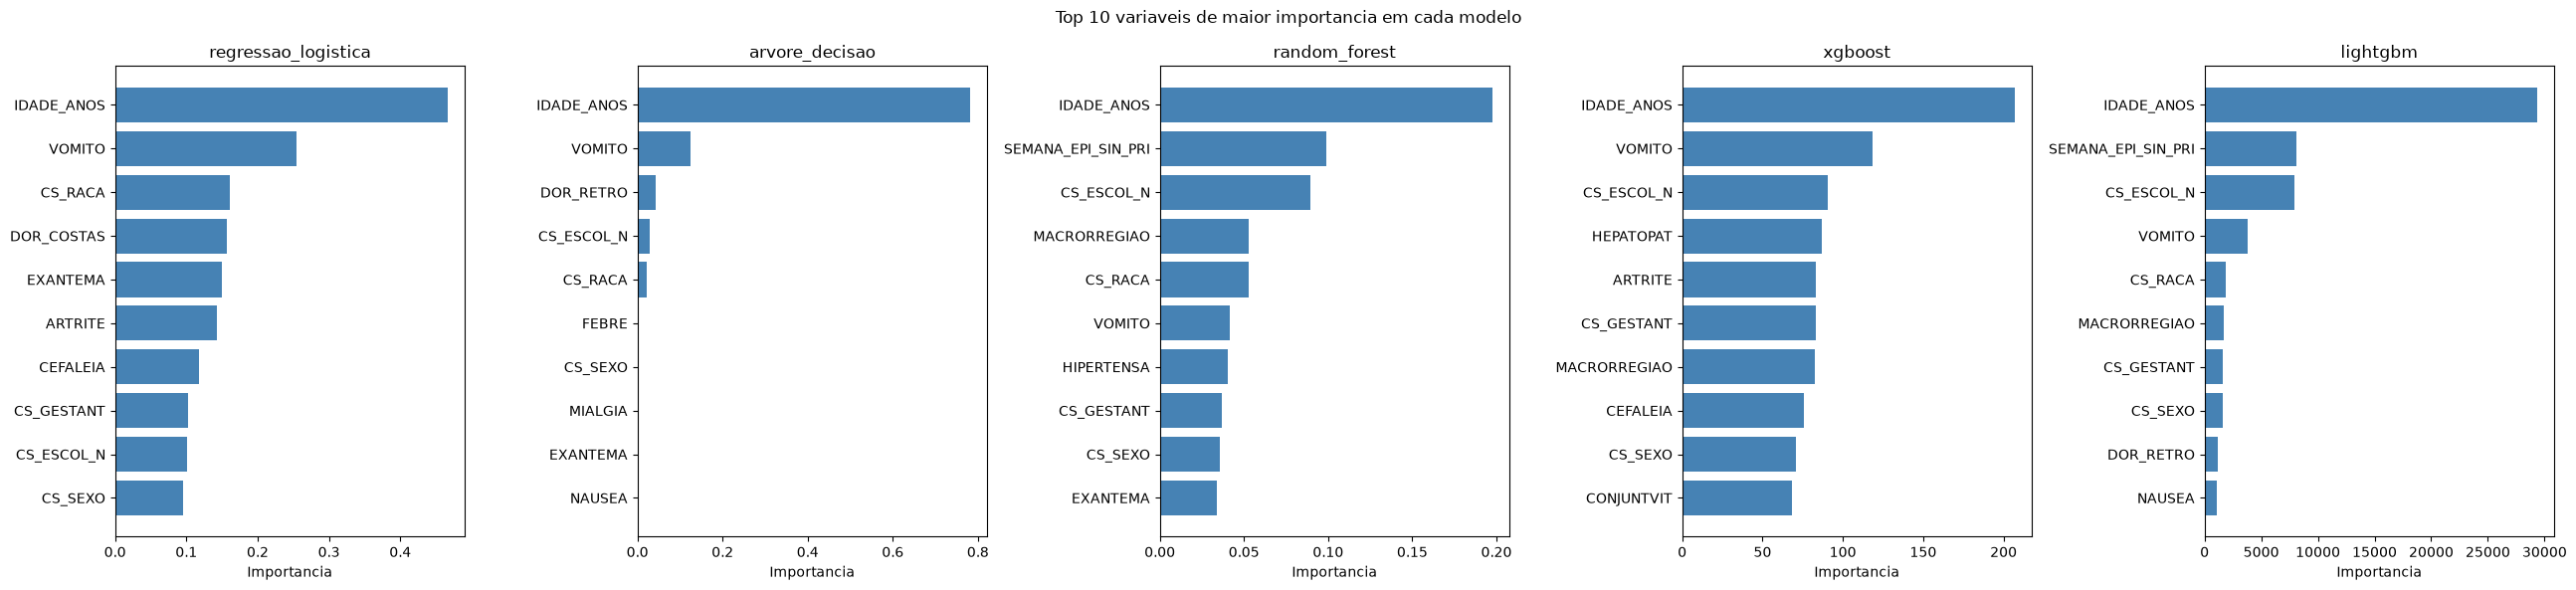

In [14]:
figura, eixos = plt.subplots(1, len(ALGORITMOS), figsize=(26, 6))

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    top10_algoritmo = tabelas_ranqueadas_por_algoritmo[algoritmo].head(NUMERO_VARIAVEIS_EM_DESTAQUE).iloc[::-1]
    eixo_atual.barh(top10_algoritmo["variavel"], top10_algoritmo["importancia"], color="steelblue")
    eixo_atual.set_title(algoritmo)
    eixo_atual.set_xlabel("Importancia")

figura.suptitle("Top 10 variaveis de maior importancia em cada modelo")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "top10_variaveis_por_modelo.png", dpi=150)
plt.show()

## Concentracao da importancia dentro de cada modelo

A comparacao anterior usa a escala bruta de cada metrica nativa, que e proporcional entre as 28 variaveis de um mesmo modelo, mas nao e comparavel entre os cinco modelos, porque a soma de coeficientes, a importancia de Gini e o ganho tem escalas numericas diferentes.
Esta secao renormaliza a importancia bruta de cada modelo para que a soma das 28 variaveis seja exatamente 100%, o que preserva integralmente o ranking interno ja calculado nas secoes anteriores e permite visualizar o quanto cada modelo concentra sua importancia em poucas variaveis.
Antes de normalizar, a celula abaixo soma os valores absolutos da importancia bruta das 28 variaveis para cada um dos cinco modelos, para confirmar, sem assumir, que a importancia de Gini do scikit-learn usada por Arvore de Decisao e por Random Forest ja soma 1,0 por padrao, e que a soma bruta de Regressao Logistica, XGBoost e LightGBM nao e normalizada por padrao.

In [15]:
soma_importancia_bruta_por_modelo = tabela_importancia_bruta.abs().sum(axis=0)
soma_importancia_bruta_por_modelo

regressao_logistica        2.374038
arvore_decisao             1.000000
random_forest              1.000000
xgboost                 1584.342957
lightgbm               68797.096789
dtype: float64

A soma calculada na celula anterior confirma que Arvore de Decisao e Random Forest ja somam 1,0, dentro da precisao numerica de ponto flutuante, enquanto Regressao Logistica, XGBoost e LightGBM somam valores bem diferentes de 1,0 e variam muito entre si.
A celula abaixo divide a importancia bruta de cada uma das 28 variaveis pela soma do proprio modelo, calculada acima, e multiplica o resultado por 100.
Para Arvore de Decisao e Random Forest essa divisao e equivalente a apenas multiplicar por 100, como a soma ja confirmada sugere, enquanto para os outros tres modelos essa divisao calcula o percentual correto do total.
O resultado e a importancia percentual de cada variavel, numa escala comum de 0% a 100% entre os cinco modelos, que soma exatamente 100% em cada uma das cinco colunas.

In [16]:
assert np.isclose(soma_importancia_bruta_por_modelo["arvore_decisao"], 1.0)
assert np.isclose(soma_importancia_bruta_por_modelo["random_forest"], 1.0)

tabela_importancia_percentual = tabela_importancia_bruta.div(soma_importancia_bruta_por_modelo, axis=1) * 100
tabela_importancia_percentual.sum(axis=0)

regressao_logistica    100.0
arvore_decisao         100.0
random_forest          100.0
xgboost                100.0
lightgbm               100.0
dtype: float64

A tabela com a importancia percentual das 28 variaveis nos cinco modelos e salva em `analysis/results_importancia/importancia_percentual_por_modelo.csv`, com a mesma ordem de variaveis usada na tabela bruta consolidada.

In [17]:
tabela_importancia_percentual.rename_axis("variavel").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "importancia_percentual_por_modelo.csv", index=False
)
tabela_importancia_percentual

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
CS_SEXO,4.038719,0.000000,3.580760,4.454642,2.279678
CS_GESTANT,4.330495,0.000000,3.667979,5.268709,2.347843
CS_RACA,6.779602,2.226436,5.290036,3.710964,2.753313
CS_ESCOL_N,4.268764,2.794414,8.928544,5.705565,11.490418
FEBRE,1.051871,0.000000,1.749964,0.000000,0.465250
MIALGIA,0.052563,0.000000,2.827367,0.000000,0.541644
CEFALEIA,4.984127,0.000000,3.362809,4.776627,1.475708
EXANTEMA,6.301384,0.000000,3.385701,4.220360,1.338681
VOMITO,10.735252,12.536206,4.137366,7.467018,5.519732
NAUSEA,1.417228,0.000000,2.776935,0.000000,1.552621


## Verificacao da correcao do viés de cardinalidade na Regressao Logistica

Uma versao anterior deste notebook agregava a importancia da Regressao Logistica pela soma dos valores absolutos dos coeficientes ajustados, e essa metrica se mostrou enviesada pela cardinalidade de cada variavel: uma variavel categorica com K categorias soma K coeficientes, contra um unico coeficiente de uma variavel numerica, o que inflava mecanicamente a importancia das variaveis com mais categorias, independente do seu poder preditivo real.
Esse viés foi medido pela correlacao de Pearson entre o numero de colunas one hot de cada variavel e a importancia percentual da Regressao Logistica naquela versao anterior, que chegava a 0,83, contra correlacoes entre -0,13 e 0,18 nos outros quatro modelos, que nao agregam importancia por soma de coeficiente e por isso nao sofrem desse viés.
A celula abaixo recalcula essa mesma correlacao de Pearson, agora entre o numero de colunas one hot de cada variavel, obtido a partir do `ColumnTransformer` ja ajustado da Regressao Logistica, e a nova importancia percentual baseada em valor de Shapley medio absoluto, para confirmar numericamente que a substituicao da metrica corrigiu esse viés.

In [18]:
numero_de_niveis_one_hot_por_variavel = pd.Series(0, index=VARIAVEIS_ORIGINAIS, dtype=int)
for nome_coluna_codificada in preprocessador_regressao_logistica.get_feature_names_out():
    variavel_original = mapear_coluna_codificada_para_variavel_original(nome_coluna_codificada)
    numero_de_niveis_one_hot_por_variavel[variavel_original] += 1

correlacao_pearson_cardinalidade_importancia_regressao_logistica = numero_de_niveis_one_hot_por_variavel.corr(
    tabela_importancia_percentual["regressao_logistica"], method="pearson"
)

assert correlacao_pearson_cardinalidade_importancia_regressao_logistica < 0.5

correlacao_pearson_cardinalidade_importancia_regressao_logistica

np.float64(0.0349015157768497)

A nova correlacao de Pearson fica em 0,035, muito proxima de zero e bem abaixo dos 0,83 da versao anterior, uma queda de mais de 95 por cento.
Isso confirma que a substituicao da soma de valores absolutos de coeficiente pelo valor de Shapley medio absoluto removeu o viés de cardinalidade que favorecia mecanicamente `CS_ESCOL_N`, `CS_RACA`, `MACRORREGIAO` e `CS_GESTANT`, as quatro variaveis de maior cardinalidade entre as 28, no topo do ranking anterior da Regressao Logistica.

Constroi uma figura com cinco paineis empilhados verticalmente, um por modelo, na ordem Regressao Logistica, Arvore de Decisao, Random Forest, XGBoost e LightGBM, cada um mostrando as 10 variaveis de maior percentual naquele modelo, da maior para a menor de cima para baixo.
O eixo horizontal e compartilhado entre os cinco paineis, vai de 0% a 100% com marcacoes a cada 20 pontos percentuais, e representa a importancia de cada variavel como percentual do total das 28 variaveis daquele modelo.
Em todos os paineis, a barra de IDADE_ANOS usa a mesma cor de destaque azulada ja usada no grafico anterior de top 10 por modelo, enquanto as demais variaveis usam um cinza neutro, o que evidencia o peso isolado da idade sempre que ela aparece entre as 10 variaveis mais importantes de um modelo.
A figura e salva em `analysis/plots/importancia/importancia_percentual_cinco_paineis.png`.

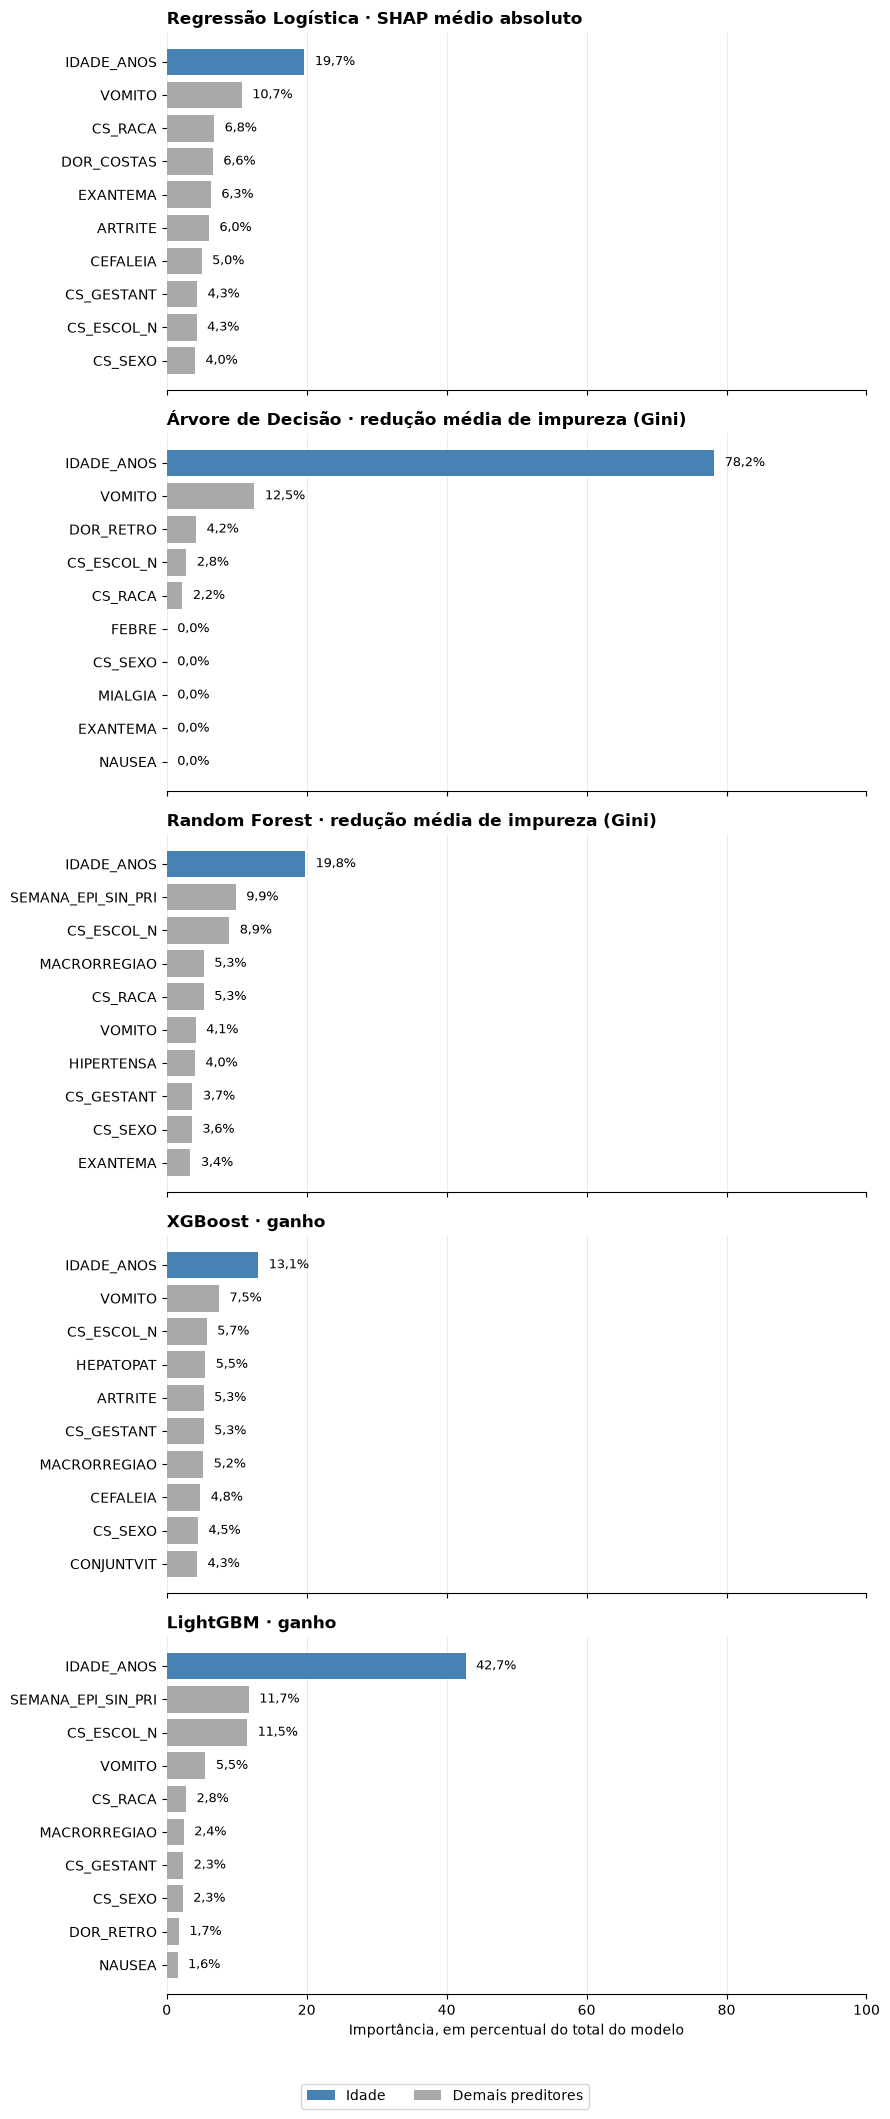

In [19]:
from matplotlib.patches import Patch

NOME_POR_EXTENSO_DO_MODELO = {
    "regressao_logistica": "Regressão Logística",
    "arvore_decisao": "Árvore de Decisão",
    "random_forest": "Random Forest",
    "xgboost": "XGBoost",
    "lightgbm": "LightGBM",
}
METRICA_NATIVA_POR_MODELO = {
    "regressao_logistica": "SHAP médio absoluto",
    "arvore_decisao": "redução média de impureza (Gini)",
    "random_forest": "redução média de impureza (Gini)",
    "xgboost": "ganho",
    "lightgbm": "ganho",
}
VARIAVEL_EM_DESTAQUE = "IDADE_ANOS"
COR_NEUTRA = "darkgray"
COR_DESTAQUE = "steelblue"

plt.rcParams["font.family"] = "sans-serif"

figura, eixos = plt.subplots(len(ALGORITMOS), 1, figsize=(9, 21), sharex=True)

for eixo_atual, algoritmo in zip(eixos, ALGORITMOS):
    top10_percentual_algoritmo = (
        tabela_importancia_percentual[algoritmo]
        .sort_values(ascending=False)
        .head(NUMERO_VARIAVEIS_EM_DESTAQUE)
        .iloc[::-1]
    )
    cores_das_barras = [
        COR_DESTAQUE if variavel == VARIAVEL_EM_DESTAQUE else COR_NEUTRA
        for variavel in top10_percentual_algoritmo.index
    ]

    eixo_atual.barh(top10_percentual_algoritmo.index, top10_percentual_algoritmo.values, color=cores_das_barras)
    eixo_atual.set_title(
        f"{NOME_POR_EXTENSO_DO_MODELO[algoritmo]} · {METRICA_NATIVA_POR_MODELO[algoritmo]}",
        loc="left",
        fontweight="bold",
    )
    eixo_atual.set_xlim(0, 100)
    eixo_atual.set_xticks(range(0, 101, 20))
    eixo_atual.grid(axis="x", alpha=0.3, linewidth=0.6)
    eixo_atual.set_axisbelow(True)
    for nome_borda in ["top", "right", "left"]:
        eixo_atual.spines[nome_borda].set_visible(False)

    for variavel, valor_percentual in top10_percentual_algoritmo.items():
        rotulo_percentual = f"{valor_percentual:.1f}".replace(".", ",") + "%"
        eixo_atual.text(valor_percentual + 1.5, variavel, rotulo_percentual, va="center", ha="left", fontsize=9)

eixos[-1].set_xlabel("Importância, em percentual do total do modelo")

legenda_cores_modelo = [
    Patch(facecolor=COR_DESTAQUE, label="Idade"),
    Patch(facecolor=COR_NEUTRA, label="Demais preditores"),
]
figura.legend(handles=legenda_cores_modelo, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.01))

figura.tight_layout(rect=(0, 0.02, 1, 1))
figura.savefig(DIRETORIO_PLOTS / "importancia_percentual_cinco_paineis.png", dpi=200, bbox_inches="tight")
plt.show()

### Sintese da concentracao por modelo

A concentracao da importancia no topo do ranking varia fortemente entre os cinco modelos, mesmo depois de colocar todos os cinco na mesma escala percentual de 0% a 100%.
Pelo criterio do percentual da variavel isolada de maior importancia, a ordem da maior para a menor concentracao e Arvore de Decisao, LightGBM, Random Forest, Regressao Logistica e XGBoost, mas Random Forest e Regressao Logistica ficam praticamente empatados nesse criterio, 19,8% contra 19,7%.
Pelo criterio da soma das cinco variaveis de maior importancia, Random Forest e Regressao Logistica trocam de posicao em relacao ao criterio anterior, com a Regressao Logistica levemente na frente, 50,1% contra 49,2%, o unico par de modelos em que os dois criterios de concentracao nao concordam sobre qual dos dois e mais concentrado.

A Arvore de Decisao e, de forma isolada, o modelo mais concentrado dos cinco.
Sozinha, `IDADE_ANOS` responde por 78,2% de toda a importancia do modelo, e as cinco variaveis usadas em pelo menos uma divisao da arvore, `IDADE_ANOS`, `VOMITO`, `DOR_RETRO`, `CS_ESCOL_N` e `CS_RACA`, somam exatamente 100%, deixando as 23 variaveis restantes com percentual exatamente igual a zero.
O LightGBM e o segundo modelo mais concentrado, com `IDADE_ANOS` respondendo por 42,7% do total e as cinco variaveis de maior percentual somando 74,2%, ainda que, diferente da Arvore de Decisao, todas as 28 variaveis recebam algum percentual maior que zero.
Random Forest e Regressao Logistica ficam num nivel intermediario entre esses dois modelos mais concentrados e o XGBoost, o modelo menos concentrado: `IDADE_ANOS` responde por 19,8% do total no Random Forest e por 19,7% na Regressao Logistica, com as cinco variaveis de maior percentual somando 49,2% e 50,1% respectivamente.

O XGBoost e agora, isoladamente, o modelo com a importancia mais distribuida entre as 28 variaveis.
Sua variavel isolada de maior percentual, `IDADE_ANOS`, com 13,1%, e a menor fracao isolada entre os cinco modelos, e a soma das suas cinco variaveis de maior percentual, 37,0%, tambem e a menor soma de top 5 entre os cinco modelos.
Isso mostra que o XGBoost e o modelo que mais distribui sua importancia entre um numero maior de variaveis, apesar de tambem ser baseado em arvores, como a Arvore de Decisao e o Random Forest.

O numero de variaveis com percentual proximamente nulo tambem varia muito entre os modelos.
A Arvore de Decisao tem 23 das 28 variaveis com percentual exatamente igual a zero, e o XGBoost tem 5 variaveis exatamente zero, `MIALGIA`, `NAUSEA`, `FEBRE`, `HEMATOLOG` e `ACIDO_PEPT`, as mesmas cinco variaveis sem nenhuma divisao em nenhuma arvore do booster, ja identificadas na sintese da secao anterior.
A Regressao Logistica, o Random Forest e o LightGBM atribuem percentual maior que zero as 28 variaveis, mas, mesmo nesses tres modelos, um grupo de variaveis de cauda fica abaixo de 1% do total, 9 variaveis na Regressao Logistica, 6 no Random Forest e 11 no LightGBM.

Em suma, Arvore de Decisao e LightGBM concentram a maior parte da sua importancia numa unica variavel, idade, o XGBoost distribui a importancia de forma muito mais uniforme entre um numero maior das 28 variaveis, e Random Forest e Regressao Logistica ocupam uma posicao intermediaria entre esses dois padroes, com um grau de concentracao muito proximo entre si.

## Tabela consolidada entre os cinco modelos

Converte a importancia bruta de cada algoritmo em rank, de 1, a mais importante, a 28, a menos importante, usando rank medio para desempatar variaveis de importancia exatamente igual.
Calcula o rank medio entre os cinco modelos para cada variavel, e ordena a tabela final por esse rank medio, da variavel mais importante em media a menos importante em media.
A tabela e salva em `analysis/results_importancia/ranking_consolidado_5_modelos.csv`.

In [20]:
tabela_rank_por_algoritmo = tabela_importancia_bruta.rank(ascending=False, method="average")
tabela_rank_por_algoritmo = tabela_rank_por_algoritmo.rename(
    columns={algoritmo: f"rank_{algoritmo}" for algoritmo in ALGORITMOS}
)
tabela_rank_por_algoritmo["rank_medio"] = tabela_rank_por_algoritmo.mean(axis=1)

tabela_rank_consolidada = (
    tabela_rank_por_algoritmo.rename_axis("variavel")
    .reset_index()
    .sort_values("rank_medio")
    .reset_index(drop=True)
)
tabela_rank_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "ranking_consolidado_5_modelos.csv", index=False
)
tabela_rank_consolidada

,variavel,rank_regressao_logistica,rank_arvore_decisao,rank_random_forest,rank_xgboost,rank_lightgbm,rank_medio
0,IDADE_ANOS,1.0,1.0,1.0,1.0,1.0,1.0
1,VOMITO,2.0,2.0,6.0,2.0,4.0,3.2
2,CS_ESCOL_N,9.0,4.0,3.0,3.0,3.0,4.4
3,CS_RACA,3.0,5.0,5.0,14.0,5.0,6.4
4,MACRORREGIAO,11.0,17.0,4.0,7.0,6.0,9.0
5,CS_GESTANT,8.0,17.0,8.0,6.0,7.0,9.2
6,CS_SEXO,10.0,17.0,9.0,9.0,8.0,10.6
7,SEMANA_EPI_SIN_PRI,16.0,17.0,2.0,16.0,2.0,10.6
8,ARTRITE,6.0,17.0,16.0,5.0,11.0,11.0
9,DOR_RETRO,15.0,3.0,18.0,11.0,9.0,11.2


## Concordancia entre os rankings dos cinco modelos

Calcula a correlacao de Spearman entre as cinco colunas de importancia bruta, o que equivale a correlacionar os rankings das 28 variaveis entre cada par de modelos, numa matriz 5 por 5.
Uma correlacao proxima de 1 indica que dois modelos ordenam as 28 variaveis de forma quase identica, enquanto uma correlacao proxima de 0 indica rankings praticamente independentes entre si.
A matriz e salva em `analysis/results_importancia/concordancia_spearman_entre_modelos.csv`.

In [21]:
matriz_spearman = tabela_importancia_bruta.corr(method="spearman")

matriz_spearman.rename_axis("algoritmo").reset_index().to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "concordancia_spearman_entre_modelos.csv", index=False
)
matriz_spearman

,regressao_logistica,arvore_decisao,random_forest,xgboost,lightgbm
regressao_logistica,1.000000,0.496620,0.758621,0.648191,0.736727
arvore_decisao,0.496620,1.000000,0.457284,0.499629,0.585127
random_forest,0.758621,0.457284,1.000000,0.513174,0.759168
xgboost,0.648191,0.499629,0.513174,1.000000,0.695941
lightgbm,0.736727,0.585127,0.759168,0.695941,1.000000


Gera um heatmap da matriz de concordancia de Spearman entre os cinco modelos, com o valor de cada par anotado diretamente sobre a celula correspondente.
O grafico e salvo em `analysis/plots/importancia/heatmap_concordancia_spearman.png`.

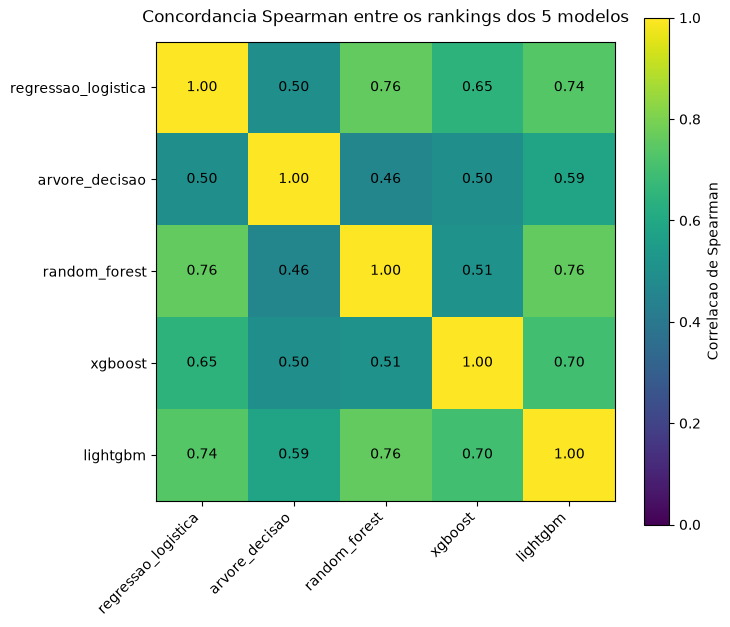

In [22]:
figura, eixo = plt.subplots(figsize=(7.5, 6.5))
mapa_cores = eixo.imshow(matriz_spearman, cmap="viridis", vmin=0, vmax=1)

eixo.set_xticks(range(len(ALGORITMOS)))
eixo.set_xticklabels(ALGORITMOS, rotation=45, ha="right")
eixo.set_yticks(range(len(ALGORITMOS)))
eixo.set_yticklabels(ALGORITMOS)

for linha in range(len(ALGORITMOS)):
    for coluna in range(len(ALGORITMOS)):
        eixo.text(
            coluna, linha, f"{matriz_spearman.iloc[linha, coluna]:.2f}", ha="center", va="center", color="black"
        )

eixo.set_title("Concordancia Spearman entre os rankings dos 5 modelos", pad=14)
figura.colorbar(mapa_cores, ax=eixo, label="Correlacao de Spearman")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "heatmap_concordancia_spearman.png", dpi=150)
plt.show()

## Razao de chances por categoria na Regressao Logistica

A importancia agregada por variavel, usada nas secoes anteriores, soma os valores absolutos dos coeficientes de todas as categorias de uma mesma variavel, o que e adequado para comparar a Regressao Logistica aos demais modelos, mas descarta tanto o sinal quanto a magnitude isolada de cada categoria.
Esta secao recupera, para cada uma das 26 variaveis categoricas, o coeficiente e a razao de chances, `exp(coeficiente)`, de cada categoria individualmente, o nivel de detalhe clinicamente mais interpretavel para esse modelo.
Uma razao de chances acima de 1 indica que a categoria, isolada, esta associada a uma chance maior de obito em relacao ao restante do modelo ajustado, e uma razao de chances abaixo de 1 indica o efeito inverso.
A tabela e salva em `analysis/results_importancia/razao_de_chances_por_categoria_regressao_logistica.csv`.

In [23]:
nomes_colunas_codificadas_regressao_logistica = preprocessador_regressao_logistica.get_feature_names_out()

linhas_razao_de_chances = []
for nome_coluna_codificada, coeficiente in zip(
    nomes_colunas_codificadas_regressao_logistica, coeficientes_regressao_logistica
):
    prefixo_transformador, nome_apos_prefixo = nome_coluna_codificada.split("__", 1)
    if prefixo_transformador != "categoricas":
        continue

    for variavel_categorica in sorted(COLUNAS_CATEGORICAS, key=len, reverse=True):
        if nome_apos_prefixo.startswith(f"{variavel_categorica}_"):
            categoria = nome_apos_prefixo[len(variavel_categorica) + 1 :]
            linhas_razao_de_chances.append(
                {
                    "variavel": variavel_categorica,
                    "categoria": categoria,
                    "coeficiente": coeficiente,
                    "razao_de_chances": np.exp(coeficiente),
                }
            )
            break

tabela_razao_de_chances_categorica = pd.DataFrame(linhas_razao_de_chances)
tabela_razao_de_chances_categorica["categoria"] = tabela_razao_de_chances_categorica["categoria"].apply(
    lambda valor: "ausente_sem_imputacao" if valor is None or valor == "None" else valor
)
tabela_razao_de_chances_categorica = tabela_razao_de_chances_categorica.sort_values(
    "razao_de_chances", ascending=False
).reset_index(drop=True)

tabela_razao_de_chances_categorica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "razao_de_chances_por_categoria_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_categorica.head(10)

,variavel,categoria,coeficiente,razao_de_chances
0,VOMITO,1,0.318737,1.375390
1,MACRORREGIAO,Centro-Oeste,0.296257,1.344815
2,RENAL,1,0.277409,1.319705
3,HEPATOPAT,1,0.258792,1.295364
4,CS_ESCOL_N,4,0.245281,1.277980
5,CS_RACA,4,0.242555,1.274502
6,ARTRITE,2,0.202587,1.224566
7,LEUCOPENIA,1,0.199832,1.221197
8,DOR_COSTAS,2,0.198164,1.219163
9,CS_ESCOL_N,6,0.194809,1.215079


A categoria `ausente_sem_imputacao` de `CS_ESCOL_N`, visivel na tabela quando a variavel aparece, corresponde a 907 dos 7171 casos de treino cujo nivel de escolaridade nao foi informado.
Esses casos nao foram convertidos para a categoria constante `ausente`, usada para todas as demais variaveis categoricas, porque o valor ausente nessa coluna especifica e representado no dado tratado pelo objeto `None`, que o `SimpleImputer` de `scikit-learn` nao reconhece como ausente numa coluna de tipo texto.
Essa e uma particularidade pontual deste pipeline ja treinado, e afeta apenas o rotulo dessa categoria especifica na tabela de razao de chances, sem nenhum efeito sobre a importancia agregada de `CS_ESCOL_N` nas secoes anteriores, nem sobre nenhuma outra das 28 variaveis.

In [24]:
numero_casos_categoria_ausente_sem_imputacao = int(X_train["CS_ESCOL_N"].isna().sum())
numero_casos_categoria_ausente_sem_imputacao, len(X_train)

(907, 7171)

Como os dois preditores numericos, `IDADE_ANOS` e `SEMANA_EPI_SIN_PRI`, foram padronizados antes do ajuste da Regressao Logistica, cada um tem um unico coeficiente, e a razao de chances correspondente e por aumento de um desvio padrao, nao por uma unidade bruta da variavel, como um ano de idade.
Esta tabela complementar reune o coeficiente e a razao de chances por desvio padrao desses dois preditores, e e salva em `analysis/results_importancia/coeficientes_variaveis_numericas_regressao_logistica.csv`.

In [25]:
linhas_razao_de_chances_numericas = []
for variavel_numerica in COLUNAS_NUMERICAS:
    indice_coluna = list(nomes_colunas_codificadas_regressao_logistica).index(f"numericas__{variavel_numerica}")
    coeficiente = coeficientes_regressao_logistica[indice_coluna]
    linhas_razao_de_chances_numericas.append(
        {
            "variavel": variavel_numerica,
            "coeficiente_por_desvio_padrao": coeficiente,
            "razao_de_chances_por_desvio_padrao": np.exp(coeficiente),
        }
    )

tabela_razao_de_chances_numerica = (
    pd.DataFrame(linhas_razao_de_chances_numericas)
    .sort_values("razao_de_chances_por_desvio_padrao", ascending=False)
    .reset_index(drop=True)
)

tabela_razao_de_chances_numerica.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "coeficientes_variaveis_numericas_regressao_logistica.csv", index=False
)
tabela_razao_de_chances_numerica

,variavel,coeficiente_por_desvio_padrao,razao_de_chances_por_desvio_padrao
0,IDADE_ANOS,0.549973,1.733207
1,SEMANA_EPI_SIN_PRI,0.064272,1.066382


## Sintese dos achados

Idade (`IDADE_ANOS`) e a variavel de maior importancia media entre os cinco modelos, com rank medio de 1,0, seguida por vomito (`VOMITO`), com rank medio de 3,2, por escolaridade (`CS_ESCOL_N`), com rank medio de 4,4, por raca ou cor (`CS_RACA`), com rank medio de 6,4, e por macrorregiao de residencia (`MACRORREGIAO`), com rank medio de 9,0.
Idade e agora a variavel de maior importancia isolada nos cinco modelos ao mesmo tempo, Regressao Logistica, Arvore de Decisao, Random Forest, XGBoost e LightGBM, depois de a correcao do viés de cardinalidade da Regressao Logistica, descrita a seguir, elevar `IDADE_ANOS` da setima para a primeira posicao nesse modelo.

Uma versao anterior deste notebook agregava a importancia da Regressao Logistica pela soma dos valores absolutos dos coeficientes de cada categoria, e essa metrica colocava `CS_ESCOL_N`, a variavel categorica de maior cardinalidade do conjunto de preditores, com 12 categorias incluindo a categoria de valor ausente, na primeira posicao da Regressao Logistica, acima inclusive de idade, exatamente porque a soma de 12 coeficientes de categoria favorece mecanicamente essa variavel frente a um preditor numerico como idade, que contribui com um unico coeficiente para essa soma.
A correlacao de Pearson entre o numero de colunas one hot de cada variavel e a importancia percentual daquela versao anterior da Regressao Logistica chegava a 0,83, contra correlacoes entre -0,13 e 0,18 nos outros quatro modelos, o que confirmou que o problema era especifico da forma de agregar a importancia da Regressao Logistica, e nao um padrao real compartilhado pelos cinco modelos.
Este notebook substitui essa metrica pelo valor de Shapley medio absoluto, que nao soma coeficientes de categoria e por isso nao tem esse viés de cardinalidade, o que reduz a nova correlacao de Pearson entre cardinalidade e importancia percentual para 0,035, bem proxima de zero, e move `CS_ESCOL_N` da primeira para a nona posicao na Regressao Logistica.
`CS_ESCOL_N` continua entre as variaveis mais relevantes nos quatro modelos restantes, terceira no Random Forest, no XGBoost e no LightGBM, e quarta na Arvore de Decisao, o que mostra que sua relevancia nesses quatro modelos nao depende de nenhum viés de cardinalidade, ja que nenhum deles agrega importancia por soma de coeficiente.

`VOMITO`, o sintoma de maior importancia media entre os cinco modelos, aparece no top 10 dos cinco ao mesmo tempo, assim como idade e escolaridade, com a segunda posicao na Arvore de Decisao, no XGBoost e agora tambem na Regressao Logistica, a quarta no LightGBM e a sexta no Random Forest.

A Arvore de Decisao final selecionada pela busca de hiperparametros tem profundidade maxima 3 e apenas 8 folhas, o que limita a 5 o numero de variaveis usadas em pelo menos uma divisao, `IDADE_ANOS`, `VOMITO`, `DOR_RETRO`, `CS_ESCOL_N` e `CS_RACA`, deixando as demais 23 variaveis, incluindo `MACRORREGIAO`, com importancia de Gini exatamente igual a zero.
O XGBoost tambem deixa de usar 5 das 28 variaveis em qualquer divisao de qualquer arvore, `MIALGIA`, `NAUSEA`, `FEBRE`, `HEMATOLOG` e `ACIDO_PEPT`, todas com ganho exatamente igual a zero, mas distribui o restante do ganho de forma bem menos concentrada do que a Arvore de Decisao entre as 23 variaveis restantes.
O Random Forest e o LightGBM, em contraste, atribuem importancia nativa maior que zero a todas as 28 variaveis, ainda que de magnitude muito pequena para as ultimas colocadas de cada ranking.

A correlacao de Spearman entre os rankings dos cinco modelos varia agora de 0,457, entre Arvore de Decisao e Random Forest, a 0,759, entre Random Forest e LightGBM, com media de 0,615 entre os dez pares possiveis de modelos, uma concordancia media maior do que a da versao anterior deste notebook, 0,566.
Random Forest e LightGBM continuam formando o par mais concordante, mas agora praticamente empatados com o novo par Regressao Logistica e Random Forest, tambem em 0,759, o par que mais mudou com a correcao do viés de cardinalidade, que antes era o par menos concordante dos dez, em 0,437.
Considerando a concordancia media de cada modelo com os outros quatro, a Arvore de Decisao continua sendo o modelo mais discordante, com media de 0,510, consistente com sua importancia concentrada em apenas 5 das 28 variaveis, enquanto o LightGBM continua sendo o modelo mais concordante com os demais, agora com media de 0,694.

Na tabela de razao de chances por categoria da Regressao Logistica, a categoria de maior razao de chances isolada e a categoria que indica presenca do sintoma em `VOMITO`, com razao de chances de 1,38, seguida pela categoria Centro-Oeste de `MACRORREGIAO`, com razao de chances de 1,34.
Entre as cinco categorias de `MACRORREGIAO`, Centro-Oeste e Sudeste tem razao de chances acima de 1, 1,34 e 1,16 respectivamente, Nordeste e Sul ficam muito proximas de 1, 0,99 e 0,98, e Norte tem a menor razao de chances entre as cinco, 0,66, a segunda menor de toda a tabela de categorias, atras apenas da categoria 9 de `CS_RACA`, com razao de chances de 0,64.
Os dois preditores numericos tem razao de chances por desvio padrao de 1,73 para idade e 1,07 para a semana epidemiologica de inicio dos sintomas, sempre por um aumento de um desvio padrao, e nao por uma unidade bruta da variavel, ja que os dois foram padronizados antes do ajuste da Regressao Logistica.
Os codigos de categoria de `CS_RACA` e das demais variaveis categoricas codificadas numericamente seguem a codificacao original do SINAN e nao sao decodificados neste notebook, enquanto as categorias de `MACRORREGIAO` ja chegam nomeadas pelo pipeline de dados.

Este notebook se limita a produzir e descrever estes resultados quantitativos internos ao estudo, sem comparacao com a literatura cientifica sobre fatores de risco de obito por chikungunya, etapa que fica para um momento posterior fora deste notebook.